In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

# 차원을 축소하기 전과 차원을 축소한 후 정확도를 비교한다.

## 와인 데이터를 주성분 분석 알고리즘에 사용할 데이터를 준비한다.

In [2]:
raw_data = datasets.load_wine()

xData = raw_data.data
yData = raw_data.target

x_train, x_test, y_train, y_test = train_test_split(xData, yData, random_state=1)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

## 주성분 분석 모델을 만들고 학습 시킨다.

주성분 분석을 알고리즘을 사용하기 위해 PCA를 import 한다.

In [3]:
from sklearn.decomposition import PCA

n_components에 축소하려는 차원 크기를 지정해서 주성분 분석 모델을 만들고 학습한 후 적용시킨다.

In [4]:
model = PCA(n_components=2)
# 주성분 분석은 비지도 학습적인 접근 방법이므로 학습시 차원을 축소하려 하는 학습 데이터의 피처만 전달한다.
# model.fit(x_train)
# 학습된 주성분 분석 모델에 의해 차원이 축소된 학습 데이터를 적용한다.
# x_train_pca = model.transform(x_train)
x_train_pca = model.fit_transform(x_train)

# 테스트 데이터는 학습 데이터를 학습시킨 주성분 분석 모델로 적용만 시킨다.
x_test_pca = model.transform(x_test)

# 차원 축소 이전 데이터의 차원을 확인하면 차원 축소전의 피처 데이터는 13차원 데이터 133개로 구성되어있음을 알 수 있고 주성분 분석을 이용해 차원 축소한 데이터는
# 2차원 데이터 133개로 구성되었음을 알 수 있다.
print(x_train.shape, x_train_pca.shape, x_test.shape, x_test_pca.shape)

(133, 13) (133, 2) (45, 13) (45, 2)


## 공분산 행렬, 고유값, 고유 벡터를 확인한다.

get_covariance() 메소드로 차원 축소에 사용된 공분산 행렬을 얻어올 수 있다.

In [5]:
print(model.get_covariance().shape)
print(model.get_covariance())

(13, 13)
[[ 1.06244198  0.05588975  0.29643474 -0.14674317  0.38769443  0.25079577
   0.19779094 -0.10070718  0.17126277  0.44742545 -0.12013532  0.02879752
   0.50505224]
 [ 0.05588975  0.86510155  0.11906446  0.23837434  0.00721146 -0.39785163
  -0.4503856   0.31716671 -0.30728109  0.30100181 -0.42357315 -0.45825394
  -0.14345856]
 [ 0.29643474  0.11906446  0.72597065 -0.01380654  0.20891722  0.02618151
  -0.01633577  0.03209892  0.00824227  0.32033554 -0.17879769 -0.10868048
   0.2307792 ]
 [-0.14674317  0.23837434 -0.01380654  0.77557799 -0.13456582 -0.4028355
  -0.42487887  0.28525095 -0.30301432  0.07431753 -0.28885443 -0.36992936
  -0.2952175 ]
 [ 0.38769443  0.00721146  0.20891722 -0.13456582  0.82428285  0.22898335
   0.19490044 -0.10843832  0.16009666  0.30262412 -0.0453494   0.06951315
   0.39222323]
 [ 0.25079577 -0.39785163  0.02618151 -0.4028355   0.22898335  1.21144743
   0.7122459  -0.47784458  0.50827447 -0.11953458  0.48155509  0.61862946
   0.49873766]
 [ 0.19779094 

singular_values_ 속성으로 차원 축소에 사용된 고유값을 얻어올 수 있다.  
13차원의 피처를 2차원으로 차원을 축소시켰으므로 2개의 고유값을 확인할 수 있다.

In [6]:
print(model.singular_values_)

[24.81797394 18.31760391]


components_ 속성으로 차원 축소에 사용된 고유 벡터를 얻어올 수 있다.  
고유 벡터는 각 고유값에 대응되는 벡터로, 이 고유 벡터가 주성분 벡터가 된다.

In [7]:
print(model.components_)

[[ 0.10418545 -0.25670612 -0.01387486 -0.23907587  0.10470229  0.4007005
   0.42902734 -0.29111343  0.30307602 -0.12127653  0.31609521  0.38729685
   0.26283936]
 [ 0.49018724  0.1691503   0.30746987 -0.04459018  0.34837302  0.07966456
   0.0133774   0.02498633  0.0415164   0.50798383 -0.26045807 -0.14018631
   0.39850143]]


차원 축소를 통해 얻어진 주성분 벡터가 전체 분산 대비 설명하는 정도를 살펴본다.

explained_variance_ 속성으로 설명되는 분산을 얻어올 수 있다.  
explained_variance_ratio_ 속성으로 전체 분산대비 설명되는 분산의 비율을 얻어올 수 있다.

In [8]:
print(model.explained_variance_)
# 첫 번째 주성분은 전체 분산의 37.3%를 두 번째 주성분은 전체 분산의 18.7% 정도를 설명한다는 것을 알 수 있다.
print(model.explained_variance_ratio_)
# 첫 번째, 두 번째 주성분으로 전체 분산의 56% 정도를 설명할 수 있다.
print(sum(model.explained_variance_ratio_))

[4.66615023 2.54192889]
[0.35623588 0.19406282]
0.5502986949470537


## 주성분 분석을 통해 차원 축소된 데이터 시각화

차원 축소된 데이터를 시각화 하기 위해서 데이터프레임으로 만든다.

In [9]:
df = pd.DataFrame(x_train_pca, columns=['x', 'y'])
df['label'] = y_train
df

,x,y,label
0,2.231848,0.148603,0
1,1.364444,-0.422617,1
2,1.918072,2.014682,0
3,3.539272,2.878394,0
4,3.182320,2.020041,0
...,...,...,...
128,-1.995535,0.227742,2
129,-3.785334,0.303041,2
130,-0.530538,-1.093638,1
131,-2.625701,0.163952,2


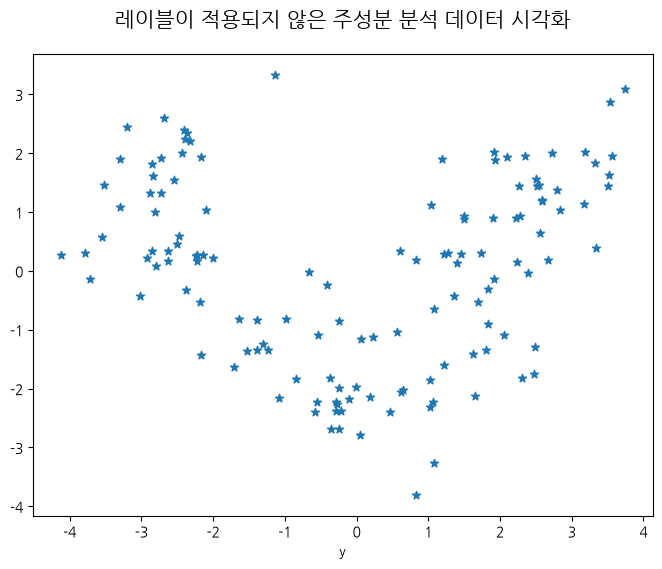

In [10]:
plt.figure(figsize=[8, 6])
plt.scatter(x=df.x, y=df.y, marker='*')
plt.title('레이블이 적용되지 않은 주성분 분석 데이터 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.xlabel('y')
plt.show()

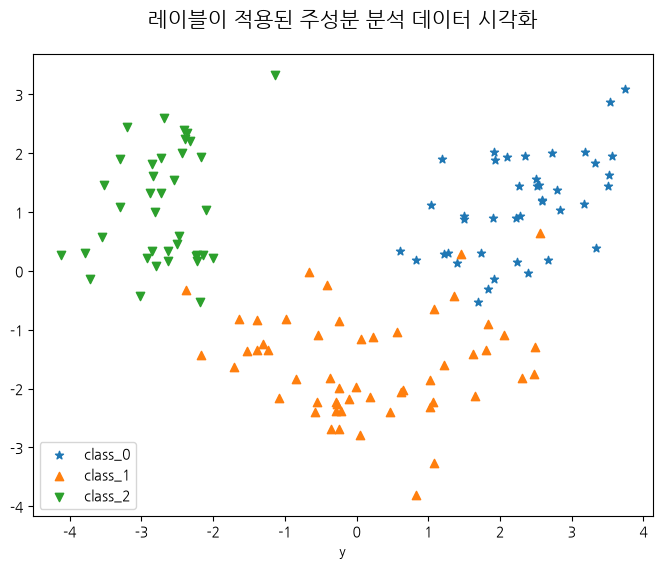

In [11]:
plt.figure(figsize=[8, 6])

# 레이블 별로 데이터를 분할한다.
df_0 = df[df.label == 0]
df_1 = df[df.label == 1]
df_2 = df[df.label == 2]

# 레이블 이름을 지정한다.
label_0 = raw_data.target_names[0]
label_1 = raw_data.target_names[1]
label_2 = raw_data.target_names[2]

# 산포도를 만든다.
plt.scatter(x=df_0.x, y=df_0.y, marker='*', label=label_0)
plt.scatter(x=df_1.x, y=df_1.y, marker='^', label=label_1)
plt.scatter(x=df_2.x, y=df_2.y, marker='v', label=label_2)

plt.title('레이블이 적용된 주성분 분석 데이터 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.xlabel('y')
plt.legend() # 범례를 표시한다.
plt.show()

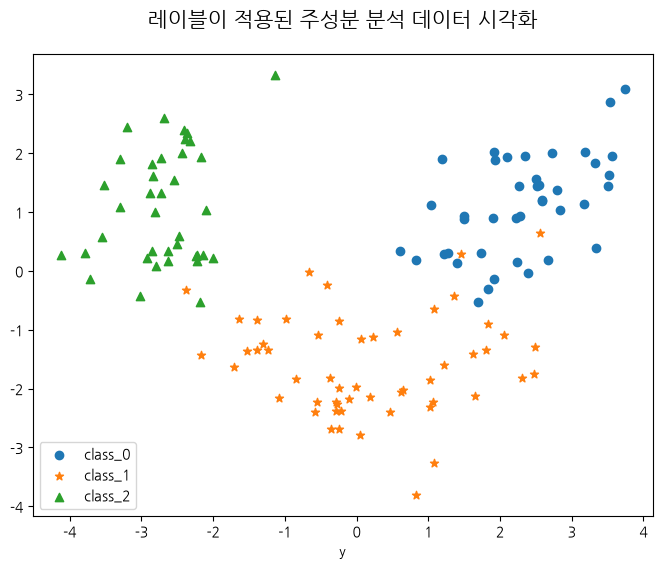

In [12]:
plt.figure(figsize=[8, 6])
markers = ['o', '*', '^', 'v', 's', 'x']

for i in range(len(raw_data.target_names)):
    df_index = df[df.label == i]
    label = raw_data.target_names[i]
    plt.scatter(x=df_index.x, y=df_index.y, label=label, marker=markers[i])

plt.title('레이블이 적용된 주성분 분석 데이터 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.xlabel('y')
plt.legend()
plt.show()

## 주성분 분석 적용 전, 후 데이터로 랜덤 포레스트 모델로 학습시키고 예측 후 평가한다.

In [13]:
from sklearn.ensemble import RandomForestClassifier

주성분 분석 전 데이터 학습 및 예측, 평가

In [14]:
model = RandomForestClassifier(random_state=0, max_depth=2).fit(x_train, y_train)
predict = model.predict(x_test)
print(predict)

[2 1 0 1 0 2 1 0 2 1 0 0 1 0 1 1 2 0 1 0 0 1 2 0 0 2 0 0 0 2 1 2 2 0 1 1 1
 1 1 0 0 1 2 0 0]


In [15]:
classification = classification_report(y_test, predict, target_names=raw_data.target_names)
print(classification)

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.94      0.97        17
     class_2       1.00      1.00      1.00        10

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



주성분 분석 후 데이터 학습 및 예측, 평가

In [16]:
model_pca = RandomForestClassifier(random_state=0, max_depth=2).fit(x_train_pca, y_train)
predict_pca = model_pca.predict(x_test_pca)
print(predict_pca)

[2 1 0 1 0 2 1 0 2 1 0 0 1 0 1 1 2 0 1 0 0 1 0 0 0 2 0 0 0 2 1 2 2 0 1 1 1
 1 1 0 0 1 2 0 0]


In [17]:
classification = classification_report(y_test, predict_pca, target_names=raw_data.target_names)
print(classification)

              precision    recall  f1-score   support

     class_0       0.90      1.00      0.95        18
     class_1       1.00      0.94      0.97        17
     class_2       1.00      0.90      0.95        10

    accuracy                           0.96        45
   macro avg       0.97      0.95      0.95        45
weighted avg       0.96      0.96      0.96        45



일반적으로 주성분 분석을 적용한 데이터의 정확도는 주성분 분석을 적용하지 않은 데이터의 정확도보다 낮게나온다.  
train_test_split() 메소드를 실행할 때 random_state를 1로 설정한 경우를 보면 주성분 분석 전 정확도가 98%, 주성분 분석 후 정확도가 96%로 나타났다. 데이터를 13차원에서 2차원으로 무려 11차원이나 줄였는데도 정도는 2% 정도의 감소로밖에 이어지지 않았다. 학습 비용을 고려할 때, 차원 축소를 이용하면 학습 비용 대비 정확도 감소가 적어서 효율적이라 볼 수 있다.

실제로 고차원 데이터의 경우, 시스템의 리소스(자원, 메모리)가 부족해 학습이 어려운 경우가 있는데 차원 축소는 이러한 문제를 해결해 준다.